Experiment No. 6
Experiment Name
Implementation and Comparative Analysis of Image Segmentation Techniques using Python
and OpenCV

Aim
To implement and evaluate various image segmentation techniques for partitioning digital
images into meaningful regions, thereby facilitating object localization, scene understanding,
and subsequent computer vision tasks.

Purpose
Image segmentation is one of the most important stages in computer vision, where an image is
divided into multiple meaningful regions or objects based on pixel intensity, color, texture, or
boundaries. Effective segmentation simplifies image analysis by isolating the regions of
interest (ROI), making tasks such as object detection, medical diagnosis, autonomous
navigation, and industrial inspection more accurate and efficient.
In this experiment, students will implement multiple image segmentation techniques, including
Thresholding, Otsu's Thresholding, Adaptive Thresholding, Watershed Segmentation, and K-
Means Clustering, and compare their performance on real-world images.

Prerequisites
• Basic knowledge of Digital Image Processing
• Familiarity with Python programming
• Python libraries: OpenCV (cv2), NumPy, Matplotlib, and Scikit-learn
• Understanding of grayscale images, image histograms, and clustering concepts
• Jupyter Notebook, Google Colab, or Visual Studio Code

Steps

1. Import the required Python libraries and load a real-world image such as a medical
   image, satellite image, or natural scene.
2. Convert the image into grayscale and perform basic preprocessing to reduce noise using
   Gaussian Blur.
3. Apply Global Thresholding to separate foreground objects from the background and
   observe the segmentation results.
4. Implement Otsu's Thresholding to automatically determine the optimal threshold value
   and compare it with global thresholding.
5. Apply Adaptive Thresholding to segment images with uneven illumination conditions.
6. Implement the Watershed Segmentation algorithm to separate overlapping or touching
   objects within the image.
7. Apply K-Means Clustering for color-based image segmentation by grouping pixels into
   distinct clusters.
8. Compare the segmentation outputs obtained from different techniques based on object
   boundaries, accuracy, and computational efficiency.
9. Visualize and analyze the segmented images to identify the most suitable technique for
   the selected dataset.
10. Summarize the observations and discuss the role of image segmentation in advanced
    computer vision applications.


Image shape: (420, 620, 3)


[ WARN:0@742.081] global loadsave.cpp:278 findDecoder imread_('image.jpg'): can't open/read file: check file path/integrity
[ WARN:0@742.081] global loadsave.cpp:278 findDecoder imread_('image.png'): can't open/read file: check file path/integrity
[ WARN:0@742.081] global loadsave.cpp:278 findDecoder imread_('sample.jpg'): can't open/read file: check file path/integrity


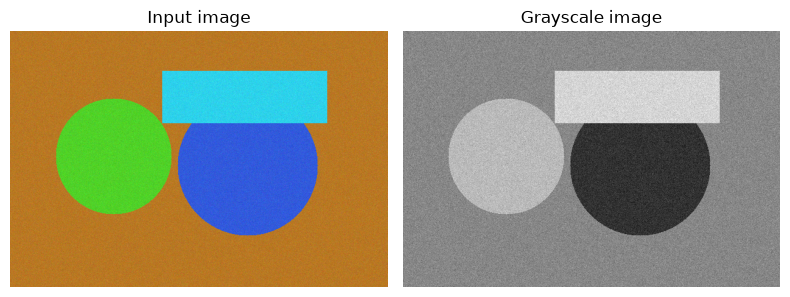

In [13]:
# Step 1: Import libraries and create/load an image
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt

try:
    from skimage import data
except ImportError:
    data = None

# Use a local sample when available; otherwise create a deterministic color scene.
image = None
for path in ("image.jpg", "image.png", "sample.jpg"):
    image = cv2.imread(path)
    if image is not None:
        break

if image is None and data is not None:
    astronaut = data.astronaut()
    image = cv2.cvtColor(astronaut, cv2.COLOR_RGB2BGR)

if image is None:
    rng = np.random.default_rng(7)
    image = np.full((420, 620, 3), (35, 120, 185), dtype=np.uint8)
    cv2.circle(image, (170, 205), 95, (40, 210, 80), -1)
    cv2.circle(image, (390, 220), 115, (220, 90, 50), -1)
    cv2.rectangle(image, (250, 65), (520, 150), (235, 210, 45), -1)
    noise = rng.normal(0, 8, image.shape).astype(np.int16)
    image = np.clip(image.astype(np.int16) + noise, 0, 255).astype(np.uint8)

image = cv2.resize(image, (620, 420))
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

print(f"Image shape: {image.shape}")
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Input image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale image")
plt.axis("off")
plt.tight_layout()
plt.show()

## Step 2: Global and Otsu Thresholding


Global threshold: 120, time: 0.308 ms
Otsu threshold: 114, time: 0.274 ms


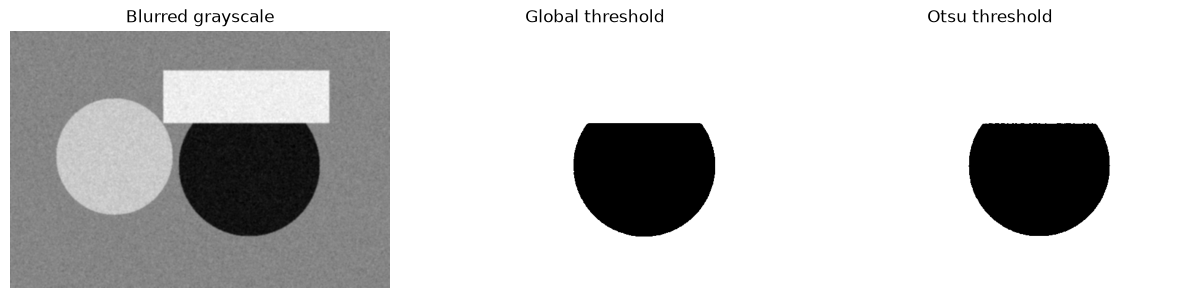

In [14]:
# A fixed threshold is simple and fast; Otsu selects a threshold from the histogram.
global_threshold = 120
t0 = time.perf_counter()
_, global_mask = cv2.threshold(blurred, global_threshold, 255, cv2.THRESH_BINARY)
global_time = time.perf_counter() - t0

t0 = time.perf_counter()
otsu_threshold, otsu_mask = cv2.threshold(
    blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
otsu_time = time.perf_counter() - t0

print(f"Global threshold: {global_threshold}, time: {global_time * 1000:.3f} ms")
print(f"Otsu threshold: {otsu_threshold:.0f}, time: {otsu_time * 1000:.3f} ms")

plt.figure(figsize=(12, 4))
for position, title, result in ((1, "Blurred grayscale", blurred), (2, "Global threshold", global_mask), (3, "Otsu threshold", otsu_mask)):
    plt.subplot(1, 3, position)
    plt.imshow(result, cmap="gray")
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()

## Step 3: Adaptive Thresholding


Adaptive thresholding time: 2.891 ms


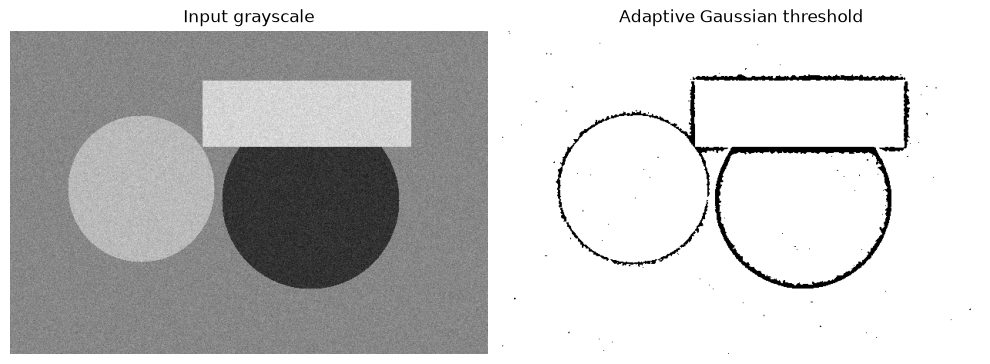

In [15]:
# Adaptive thresholding computes a local threshold for each neighborhood.
t0 = time.perf_counter()
adaptive_mask = cv2.adaptiveThreshold(
    blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,  blockSize=31, C=5
)
adaptive_time = time.perf_counter() - t0

print(f"Adaptive thresholding time: {adaptive_time * 1000:.3f} ms")
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Input grayscale")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(adaptive_mask, cmap="gray")
plt.title("Adaptive Gaussian threshold")
plt.axis("off")
plt.tight_layout()
plt.show()

## Step 4: Watershed Segmentation


Watershed regions: 2
Watershed time: 10.808 ms


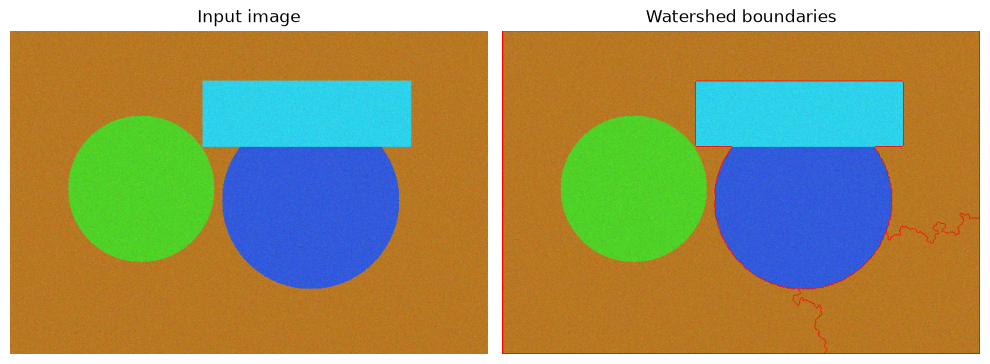

In [16]:
# Distance-transform markers separate touching foreground objects.
t0 = time.perf_counter()
foreground = cv2.morphologyEx(otsu_mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8), iterations=2)
distance = cv2.distanceTransform(foreground, cv2.DIST_L2, 5)
_, sure_foreground = cv2.threshold(distance, 0.35 * distance.max(), 255, 0)
sure_foreground = np.uint8(sure_foreground)
sure_background = cv2.dilate(foreground, np.ones((3, 3), np.uint8), iterations=3)
unknown = cv2.subtract(sure_background, sure_foreground)
marker_count, markers = cv2.connectedComponents(sure_foreground)
markers = markers + 1
markers[unknown == 255] = 0
watershed_image = image.copy()
cv2.watershed(watershed_image, markers)
watershed_image[markers == -1] = (0, 0, 255)
watershed_time = time.perf_counter() - t0

print(f"Watershed regions: {marker_count - 1}")
print(f"Watershed time: {watershed_time * 1000:.3f} ms")
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Input image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(watershed_image, cv2.COLOR_BGR2RGB))
plt.title("Watershed boundaries")
plt.axis("off")
plt.tight_layout()
plt.show()

## Step 5: K-Means Color Segmentation


K-means clusters: 4
K-means time: 84.516 ms


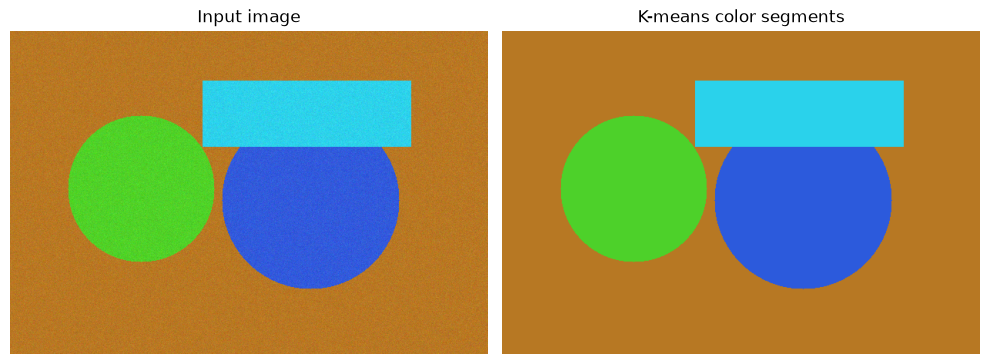

In [17]:
# K-means groups pixels by color in Lab space, which is closer to human perception.
t0 = time.perf_counter()
lab_image = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
pixels = lab_image.reshape((-1, 3)).astype(np.float32)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.2)
cluster_count = 4
_, labels, centers = cv2.kmeans(
    pixels, cluster_count, None, criteria, 10, cv2.KMEANS_PP_CENTERS
)
centers = np.uint8(centers)
kmeans_lab = centers[labels.flatten()].reshape(lab_image.shape)
kmeans_image = cv2.cvtColor(kmeans_lab, cv2.COLOR_LAB2BGR)
kmeans_time = time.perf_counter() - t0

print(f"K-means clusters: {cluster_count}")
print(f"K-means time: {kmeans_time * 1000:.3f} ms")
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Input image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(kmeans_image, cv2.COLOR_BGR2RGB))
plt.title("K-means color segments")
plt.axis("off")
plt.tight_layout()
plt.show()

## Step 6: Comparative Analysis


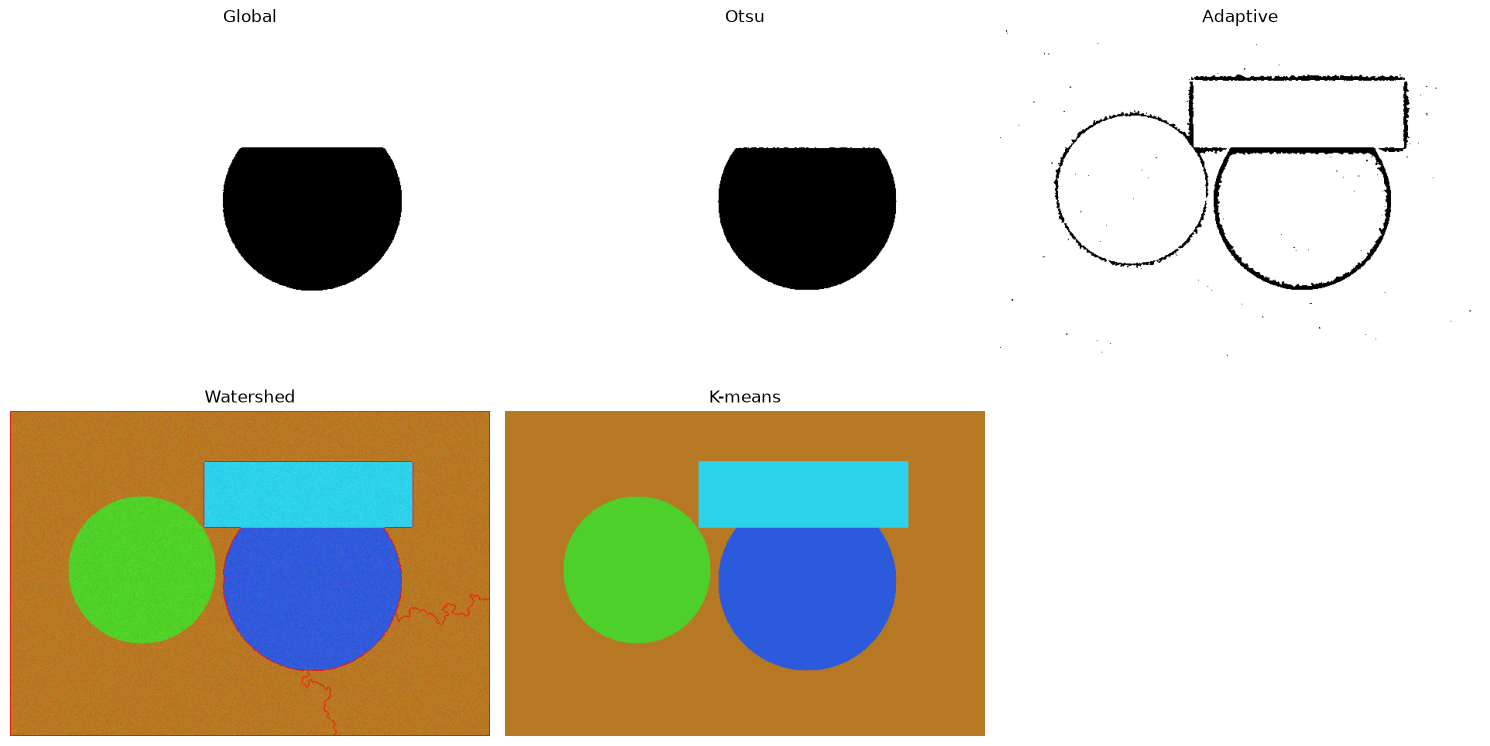

Method      Runtime (ms)
-----------------------
Global          0.308
Otsu            0.274
Adaptive        2.891
Watershed      10.808
K-means        84.516


In [18]:
# Visual comparison and a lightweight efficiency summary.
results = {
    "Global": (global_mask, global_time),
    "Otsu": (otsu_mask, otsu_time),
    "Adaptive": (adaptive_mask, adaptive_time),
    "Watershed": (watershed_image, watershed_time),
    "K-means": (kmeans_image, kmeans_time),
}

plt.figure(figsize=(15, 8))
for index, (name, (result, _)) in enumerate(results.items(), start=1):
    plt.subplot(2, 3, index)
    if result.ndim == 3:
        result = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)
        plt.imshow(result)
    else:
        plt.imshow(result, cmap="gray")
    plt.title(name)
    plt.axis("off")
plt.tight_layout()
plt.show()

print("Method      Runtime (ms)")
print("-----------------------")
for name, (_, runtime) in results.items():
    print(f"{name:<10} {runtime * 1000:>10.3f}")

## Step 7: Observations and Conclusion

- Global thresholding is the simplest and fastest method, but it is sensitive to the selected threshold and uneven illumination.
- Otsu's method chooses a data-driven threshold and is effective when the histogram has reasonably distinct foreground and background modes.
- Adaptive thresholding handles local illumination changes, although it can preserve more noise and requires neighborhood parameters.
- Watershed produces explicit boundaries and can separate touching objects when its foreground markers are good; poor markers may cause over-segmentation.
- K-means uses color information and is useful when regions have different colors, but its result depends on the number of clusters and initialization.

For this image, K-means is the most suitable choice for color-based region partitioning, while watershed is the best choice for separating touching objects. In a production system, the method should be selected according to the image characteristics and validated against labeled ground truth using metrics such as IoU, Dice score, or pixel accuracy.


Questions 
1. What is image segmentation? Why is it considered a fundamental step in computer 
vision? 
2. Differentiate between Image Segmentation and Image Classification. 
3. Explain  the  working  principle  of  Global  Thresholding,  Otsu's  Thresholding,  and 
Adaptive Thresholding. 
4. What is the Watershed Algorithm? Why is it useful for separating overlapping objects? 
5. How is K-Means Clustering applied to image segmentation? 
6. Compare threshold-based segmentation and clustering-based segmentation techniques. 
7. What challenges are encountered while segmenting images with complex backgrounds 
or varying illumination? 
8. Mention five real-world applications where image segmentation plays a critical role. 
9. How does image segmentation improve the performance of object detection and image 
recognition systems? 
10. Compare  traditional  image  segmentation  techniques  with  deep  learning-based 
segmentation methods such as U-Net and Mask R-CNN. 

Below are **exam-ready, point-wise answers** to all 10 questions on **Image Segmentation**.

## 1. What is Image Segmentation? Why is it considered a fundamental step in Computer Vision?

**Image Segmentation** is the process of dividing an image into meaningful regions or segments so that pixels belonging to the same object or region are grouped together.

### Why is it fundamental?

* It separates **foreground objects from the background**.
* It identifies the **boundaries and shapes of objects**.
* It helps in extracting important features such as **area, shape, and texture**.
* It simplifies complex images for further processing.
* It is widely used in **object detection, recognition, medical imaging, autonomous vehicles, and robotics**.

**Example:** In a medical image, segmentation can separate a tumor from surrounding healthy tissue.

---

## 2. Differentiate between Image Segmentation and Image Classification

| Image Segmentation                                  | Image Classification                                 |
| --------------------------------------------------- | ---------------------------------------------------- |
| Divides an image into different regions or objects. | Assigns a label/class to an entire image.            |
| Works at the **pixel level**.                       | Usually works at the **image level**.                |
| Provides the location and boundaries of objects.    | Only identifies what category the image belongs to.  |
| Output is a segmented/masked image.                 | Output is a class label.                             |
| Example: Identifying the exact pixels of a tumor.   | Example: Classifying an X-ray as normal or abnormal. |

**In simple words:** Classification tells **“what is in the image?”**, while segmentation tells **“where exactly is it?”**

---

## 3. Explain the working principle of Global Thresholding, Otsu's Thresholding, and Adaptive Thresholding

### A. Global Thresholding

Global thresholding uses **one fixed threshold value** for the entire image.

The basic rule is:

$$
g(x,y)=
\begin{cases}
255, & f(x,y)>T\\
0, & f(x,y)\leq T
\end{cases}
$$

Where:

* \(f(x,y)\) = original pixel intensity
* \(T\) = threshold
* \(g(x,y)\) = output binary image

**Working:**

1. Select a threshold \(T\).
2. Compare every pixel with \(T\).
3. Pixels above \(T\) become white.
4. Pixels below \(T\) become black.

**Best suited for:** Images with relatively uniform illumination.

---

### B. Otsu's Thresholding

Otsu's method automatically determines the **optimal threshold** from the image histogram.

**Working:**

1. Calculate the histogram of the grayscale image.
2. Consider different possible threshold values.
3. Divide pixels into two classes: foreground and background.
4. Calculate the variance between the two classes.
5. Select the threshold that **maximizes between-class variance**.
6. Generate the binary segmented image.

**Advantage:** No need to manually select the threshold.

**Best suited for:** Images where foreground and background have reasonably distinct intensity distributions.

---

### C. Adaptive Thresholding

Adaptive thresholding calculates a **different threshold for different regions** of an image.

**Working:**

1. Divide the image into small neighborhoods.
2. Calculate a local threshold for each neighborhood.
3. Compare each pixel with its local threshold.
4. Classify the pixel as foreground or background.

Common methods include:

* **Mean adaptive thresholding**
* **Gaussian adaptive thresholding**

**Advantage:** Works well when illumination is **uneven or changing across the image**.

---

## 4. What is the Watershed Algorithm? Why is it useful for separating overlapping objects?

The **Watershed Algorithm** is a region-based image segmentation technique that treats an image like a **topographic surface**, where pixel intensity represents height.

### Working:

1. Convert the image into a suitable grayscale or binary representation.
2. Identify important regions called **markers**.
3. Imagine flooding the image from the lowest points.
4. As water from different regions begins to meet, boundaries called **watershed lines** are created.
5. These boundaries separate different objects.

### Why is it useful?

Watershed is particularly useful for **separating touching or overlapping objects**.

**Example:** If several coins are touching each other in an image, ordinary thresholding may detect them as one connected object. Watershed can create boundaries between the individual coins.

**Main advantage:** Provides clear boundaries between adjacent objects.

---

## 5. How is K-Means Clustering applied to Image Segmentation?

**K-Means Clustering** is an unsupervised machine learning technique that groups pixels into \(K\) clusters based on their similarity.

### Steps:

1. Represent each pixel using features such as:

   * RGB values
   * Intensity
   * Position, if required
2. Select the number of clusters \(K\).
3. Randomly initialize \(K\) cluster centers.
4. Assign each pixel to the nearest cluster center.
5. Recalculate the cluster centers.
6. Repeat assignment and recalculation until the clusters stabilize.
7. Assign each cluster a representative color or label.

### Example:

For \(K=3\):

* Cluster 1 → Sky
* Cluster 2 → Trees
* Cluster 3 → Ground

Thus, the image is divided into three meaningful regions.

**Advantage:** Does not require manually defined intensity thresholds.

---

## 6. Compare Threshold-Based and Clustering-Based Segmentation Techniques

| Feature                | Threshold-Based                                | Clustering-Based                            |
| ---------------------- | ---------------------------------------------- | ------------------------------------------- |
| Basic principle        | Separates pixels using intensity threshold(s). | Groups similar pixels into clusters.        |
| Examples               | Global, Otsu, Adaptive Thresholding            | K-Means, Fuzzy C-Means                      |
| Complexity             | Generally simple and fast.                     | Generally more computationally expensive.   |
| Number of regions      | Usually limited by selected thresholds.        | Can create multiple clusters.               |
| Parameter requirement  | Requires threshold selection or calculation.   | Requires number of clusters \(K\).          |
| Illumination variation | Can perform poorly with global thresholding.   | Can handle some variations better.          |
| Color information      | Basic methods often use grayscale.             | Can directly use RGB/HSV features.          |
| Suitable for           | Simple foreground-background separation.       | Images containing multiple regions/classes. |

**Conclusion:** Thresholding is simpler and faster, whereas clustering is more flexible for complex images.

---

## 7. What challenges are encountered while segmenting images with complex backgrounds or varying illumination?

Several challenges can make segmentation difficult:

1. **Uneven illumination** – Different parts of an image may have different brightness levels.
2. **Complex backgrounds** – Background objects may have colors or textures similar to the foreground.
3. **Shadows** – Shadows can be incorrectly identified as objects.
4. **Low contrast** – Foreground and background may have very similar intensities.
5. **Noise** – Random pixel variations can create unwanted regions.
6. **Object overlap** – Multiple objects may touch or overlap.
7. **Texture variation** – Objects with complex textures can be difficult to separate.
8. **Color similarity** – Object and background may have similar colors.
9. **Object boundaries** – Blurred or poorly defined edges make accurate segmentation difficult.

### Solutions:

* Adaptive thresholding
* Histogram equalization
* Filtering and noise removal
* Watershed algorithm
* Color-space conversion
* K-Means clustering
* Deep learning-based segmentation

---

## 8. Mention five real-world applications where Image Segmentation plays a critical role

### 1. Medical Imaging

Segmentation is used to identify **tumors, organs, tissues, and lesions** in CT, MRI, and X-ray images.

### 2. Autonomous Vehicles

It helps identify **roads, pedestrians, vehicles, traffic signs, and obstacles**.

### 3. Satellite and Remote Sensing

It separates **buildings, roads, forests, water bodies, and agricultural areas**.

### 4. Face and Human Body Analysis

It can separate a person's **face, hair, skin, and body regions** from the background.

### 5. Industrial Inspection

It is used to identify **defects, cracks, scratches, and faulty components** in manufactured products.

---

## 9. How does Image Segmentation improve the performance of Object Detection and Image Recognition systems?

Image segmentation improves these systems by providing **more precise information about individual objects and their boundaries**.

### Benefits:

* **Removes irrelevant background:** The system can concentrate on important objects.
* **Improves object localization:** Exact object boundaries can be identified.
* **Improves feature extraction:** Features can be extracted from the object rather than the entire image.
* **Handles overlapping objects:** Individual objects can be separated.
* **Improves recognition accuracy:** Cleaner object regions make classification easier.
* **Reduces background noise:** Unwanted information is eliminated.
* **Enables pixel-level analysis:** Every pixel can be assigned to an object or region.

### Example:

In autonomous driving, segmentation can identify exactly which pixels represent the **road, cars, pedestrians, and buildings**, helping subsequent detection and decision-making systems.

---

## 10. Compare Traditional Image Segmentation Techniques with Deep Learning-Based Methods such as U-Net and Mask R-CNN

| Feature             | Traditional Techniques                | U-Net                              | Mask R-CNN                                 |
| ------------------- | ------------------------------------- | ---------------------------------- | ------------------------------------------ |
| Approach            | Rule/algorithm-based                  | Deep learning                      | Deep learning                              |
| Examples            | Thresholding, Watershed, K-Means      | Semantic segmentation              | Instance segmentation                      |
| Training required   | Usually no training                   | Requires training data             | Requires training data                     |
| Feature extraction  | Manually designed/handcrafted         | Automatically learned              | Automatically learned                      |
| Accuracy            | Good for simple images                | High for many complex tasks        | High for object-level segmentation         |
| Object separation   | Can be difficult                      | Primarily class-level segmentation | Separates individual object instances      |
| Complex backgrounds | Often struggles                       | Handles complex scenes better      | Handles complex scenes better              |
| Computation         | Usually lower                         | Higher                             | Higher                                     |
| Data requirement    | Low                                   | Requires labeled datasets          | Requires labeled instance annotations      |
| Applications        | Simple industrial and document images | Medical imaging, segmentation      | Object detection and instance segmentation |

### U-Net

**U-Net** is a deep learning architecture mainly designed for **semantic segmentation**.

It has:

* **Encoder:** Extracts features and reduces spatial dimensions.
* **Decoder:** Reconstructs the segmentation map.
* **Skip connections:** Transfer fine spatial information from the encoder to the decoder.

It is particularly popular in **medical image segmentation**.

### Mask R-CNN

**Mask R-CNN** extends object detection by adding a branch that predicts a **segmentation mask for each detected object**.

It performs:

1. Object detection
2. Class prediction
3. Bounding-box prediction
4. Pixel-level mask prediction

Therefore, Mask R-CNN is suitable for **instance segmentation**, where different objects of the same class need to be distinguished.

### Overall conclusion

**Traditional methods** such as thresholding, watershed, and K-Means are simple, fast, and useful when image conditions are controlled. **Deep learning methods** such as U-Net and Mask R-CNN generally provide better performance on complex images because they learn useful features automatically, but they require substantial training data and computational resources.
